# Haunted Places in the USA 👻

Data analysis of ~11,000 reported haunted locations (TidyTuesday, October 10, 2023).

## 1. Load the data

In [1]:
import re                           # regular expressions for text processing
from collections import Counter     # counts how often each word appears

import pandas as pd                 # working with tables (DataFrames)
import matplotlib.pyplot as plt     # static charts
import plotly.express as px         # interactive charts and maps

# Read the CSV file (it must be in the same folder as this script)
df = pd.read_csv("haunted_places.csv")

# Show the size of the table: (number of rows, number of columns)
print(df.shape)

# Preview the first 5 rows to understand the structure
df.head()

(10992, 10)


,city,country,description,location,state,state_abbrev,longitude,latitude,city_longitude,city_latitude
0,Ada,United States,Ada witch - Sometimes you can see a misty blue...,Ada Cemetery,Michigan,MI,-85.504893,42.962106,-85.495480,42.960727
1,Addison,United States,A little girl was killed suddenly while waitin...,North Adams Rd.,Michigan,MI,-84.381843,41.971425,-84.347168,41.986434
2,Adrian,United States,If you take Gorman Rd. west towards Sand Creek...,Ghost Trestle,Michigan,MI,-84.035656,41.904538,-84.037166,41.897547
3,Adrian,United States,"In the 1970's, one room, room 211, in the old ...",Siena Heights University,Michigan,MI,-84.017565,41.905712,-84.037166,41.897547
4,Albion,United States,Kappa Delta Sorority - The Kappa Delta Sororit...,Albion College,Michigan,MI,-84.745177,42.244006,-84.753030,42.243097


## 2. Top 10 states by number of haunted places

state
California       1070
Texas             696
Pennsylvania      649
Michigan          529
Ohio              477
New York          459
Illinois          395
Kentucky          370
Indiana           351
Massachusetts     342
Name: count, dtype: int64


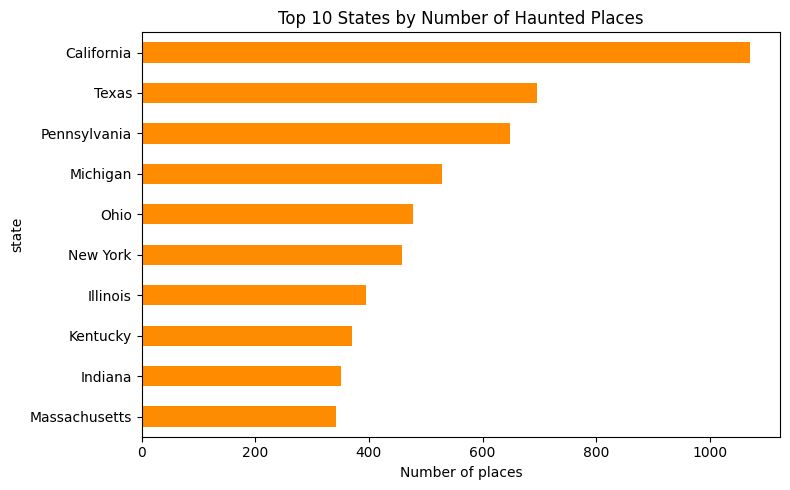

In [2]:
# Count how many haunted places each state has and keep the top 10
top_states = df["state"].value_counts().head(10)
print(top_states)

# Horizontal bar chart (sorted so the largest bar is on top)
top_states.sort_values().plot(kind="barh", color="darkorange", figsize=(8, 5))
plt.title("Top 10 States by Number of Haunted Places")
plt.xlabel("Number of places")
plt.tight_layout()
plt.show()

## 3. Map of haunted hotspots

The interactive map does not render on GitHub. [🗺️ Open the interactive map](https://katya-davydova.github.io/haunted-places-analysis/haunted_map.html)

In [3]:
# Remove rows without coordinates
geo = df.dropna(subset=["latitude", "longitude"])

# Keep only points inside a reasonable US area (removes data entry errors)
geo = geo[geo["longitude"].between(-180, -60) & geo["latitude"].between(15, 72)]

# Scatter map of the USA: each dot is one haunted place
# This map type draws state borders itself, so it works inside VS Code
fig = px.scatter_geo(
    geo,
    lat="latitude",
    lon="longitude",
    hover_name="location",      # name shown when hovering over a point
    hover_data=["city", "state"],
    scope="usa",                # show only the USA
    opacity=0.4,                # semi-transparent dots, dense areas look darker
    title="Haunted Places in the USA",
)
fig.update_traces(marker=dict(size=4, color="darkorange"))
fig.update_layout(width=1000, height=600)   # make the map bigger
fig.show()

## 4. Most common words in descriptions

night       3595
seen        3233
people      3193
old         3008
see         2529
house       2264
off         2264
ghost       2200
room        2194
man         2155
heard       2072
building    2014
hear        2008
haunted     1947
road        1864
school      1736
floor       1703
girl        1665
died        1563
cemetery    1556
dtype: int64


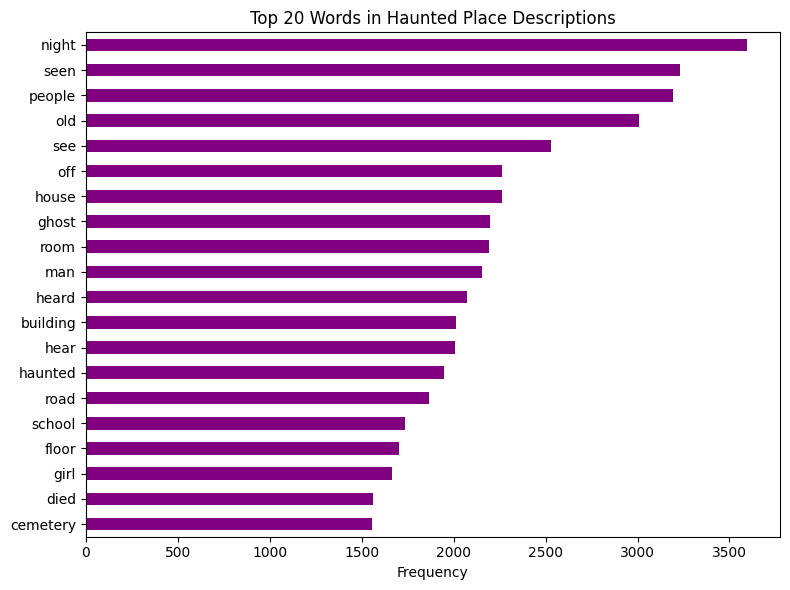

In [4]:
# Stop words are very common words that carry no meaning for our analysis
stop_words = set("""
a an the and or but if of to in on at by for with from as is was were be been
being are it its this that these those there their they them he she his her
him i you we our my me who whom which what when where why how not no so than
then too very can will would could should may might has have had do does did
said says one two also into out up down over about after before just all any
some more most other such only own same around back like still many
""".split())

# Combine all descriptions into one big lowercase text
text = " ".join(df["description"].dropna()).lower()

# Split the text into words (letters only, no numbers or punctuation)
words = re.findall(r"[a-z]+", text)

# Remove stop words and very short words (1-2 letters)
words = [w for w in words if w not in stop_words and len(w) > 2]

# Count each word and keep the 20 most frequent
top_words = pd.Series(Counter(words)).sort_values(ascending=False).head(20)
print(top_words)

# Horizontal bar chart of the top 20 words
top_words.sort_values().plot(kind="barh", color="purple", figsize=(8, 6))
plt.title("Top 20 Words in Haunted Place Descriptions")
plt.xlabel("Frequency")
plt.tight_layout()
plt.show()

## 5. Ghost types

lady in white        107
nun / monk           151
soldier              290
shadow figure        571
boy                  685
child / children    1210
girl                1457
woman / lady        1780
man                 1811
dtype: int64


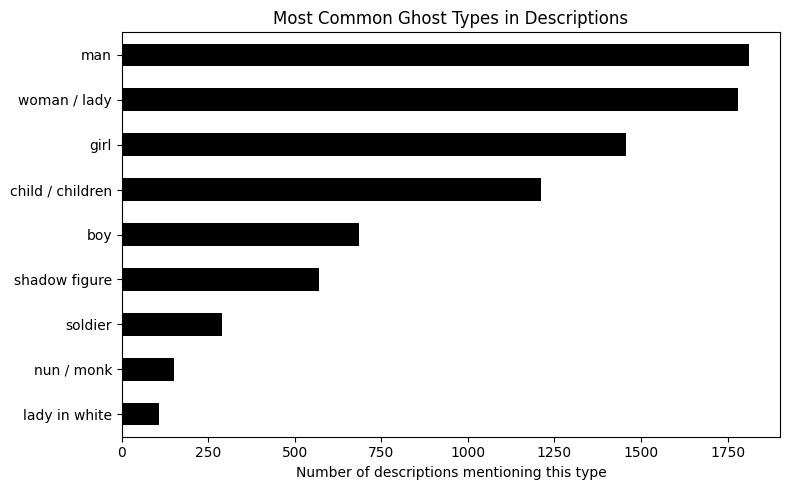

In [5]:
# Each ghost type is defined by a search pattern (regular expression)
# \b means "word boundary", so "man" will not match "woman" or "manager"
ghost_types = {
    "woman / lady": r"\b(?:woman|lady|women)\b",
    "girl": r"\bgirls?\b",
    "boy": r"\bboys?\b",
    "child / children": r"\b(?:child|children|kids?)\b",
    "man": r"\b(?:man|men)\b",
    "soldier": r"\bsoldiers?\b",
    "nun / monk": r"\b(?:nuns?|monks?)\b",
    "shadow figure": r"\bshadow",
    "lady in white": r"\b(?:white lady|lady in white|woman in white)\b",
}

# Lowercase descriptions (empty text instead of missing values)
desc = df["description"].fillna("").str.lower()

# For each ghost type, count how many descriptions mention it
counts = {name: desc.str.contains(pattern, regex=True).sum()
          for name, pattern in ghost_types.items()}

ghosts = pd.Series(counts).sort_values()
print(ghosts)

# Bar chart of ghost types
ghosts.plot(kind="barh", color="black", figsize=(8, 5))
plt.title("Most Common Ghost Types in Descriptions")
plt.xlabel("Number of descriptions mentioning this type")
plt.tight_layout()
plt.show()